# Section 1: Lotka-Volterra Equations

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp



In [ ]:
t = sp.symbols("t")
x = sp.Function("x")
y = sp.Function("y")
alpha, beta, gamma, delta = (2, 4, 1, 3)

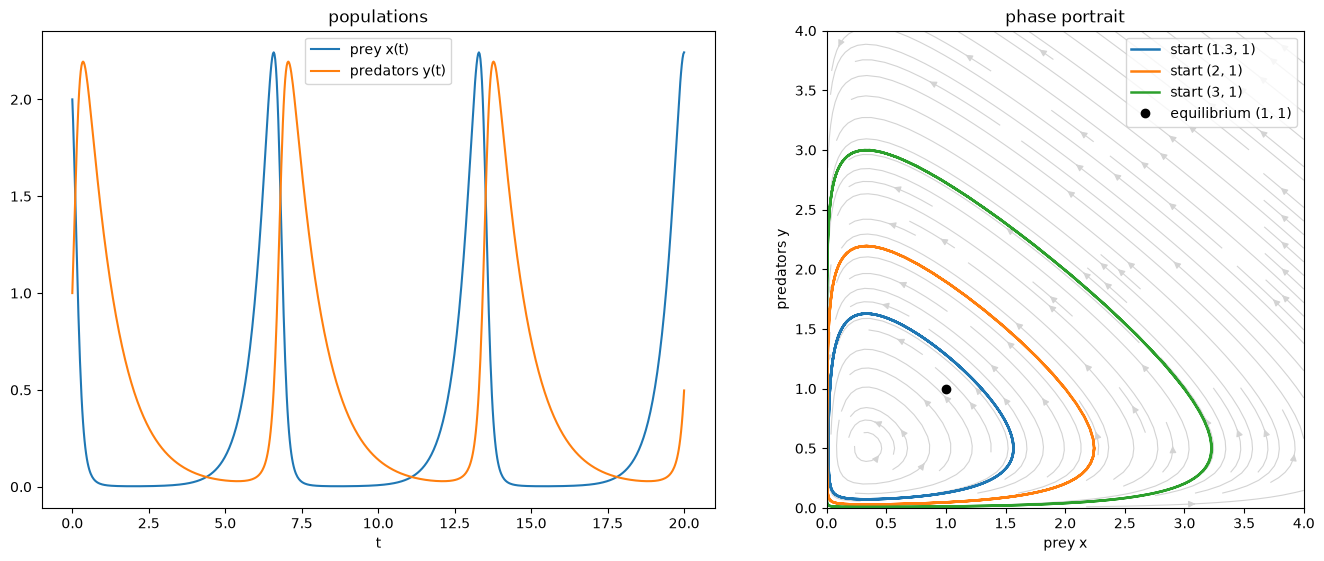

In [35]:
def LV(t, u):
    x, y = u
    return [alpha * x - beta * x * y, delta * x * y - gamma * y]

tt = np.linspace(0, 20, 800)
sol = solve_ivp(LV, (0, 20), [2, 1], t_eval=tt, rtol=1e-9, atol=1e-12)

xs = np.linspace(0.01, 4, 21)
Xg, Yg = np.meshgrid(xs, xs)
U, V = LV(0, [Xg, Yg])

fig, axs = plt.subplots(1, 2, figsize=(14, 5.5), constrained_layout=True)
axs[0].plot(tt, sol.y[0], label="prey x(t)")
axs[0].plot(tt, sol.y[1], label="predators y(t)")
axs[0].set_xlabel("t"); axs[0].legend(); axs[0].set_title("populations")

axs[1].streamplot(Xg, Yg, U, V, color="lightgray", density=1.2, linewidth=0.8)
for x0 in [1.3, 2, 3]:
    s = solve_ivp(LV, (0, 20), [x0, 1], t_eval=tt, rtol=1e-9, atol=1e-12)
    axs[1].plot(s.y[0], s.y[1], lw=1.8, label=f"start ({x0}, 1)")
axs[1].plot(1, 1, "o", color="k", label="equilibrium (1, 1)")
axs[1].set_xlim(0, 4); axs[1].set_ylim(0, 4); axs[1].set_aspect("equal")
axs[1].set_xlabel("prey x"); axs[1].set_ylabel("predators y"); axs[1].legend(loc="upper right")
axs[1].set_title("phase portrait")
plt.show()

# Section 2: The Lorenz System


In [58]:
#Definition of the system, with initial conditions that cause chaotic behavior (those being sigma = 10, rho = 28, and beta = 8/3 as outlined in the initial paper)
def lorenz(t, pos, sigma = 10, rho = 28, beta = 8/3):
    x, y, z = pos
    dx = sigma*(y-x)
    dy = x*(rho - z) - y
    dz = x*y - beta *z

    return [dx, dy, dz]

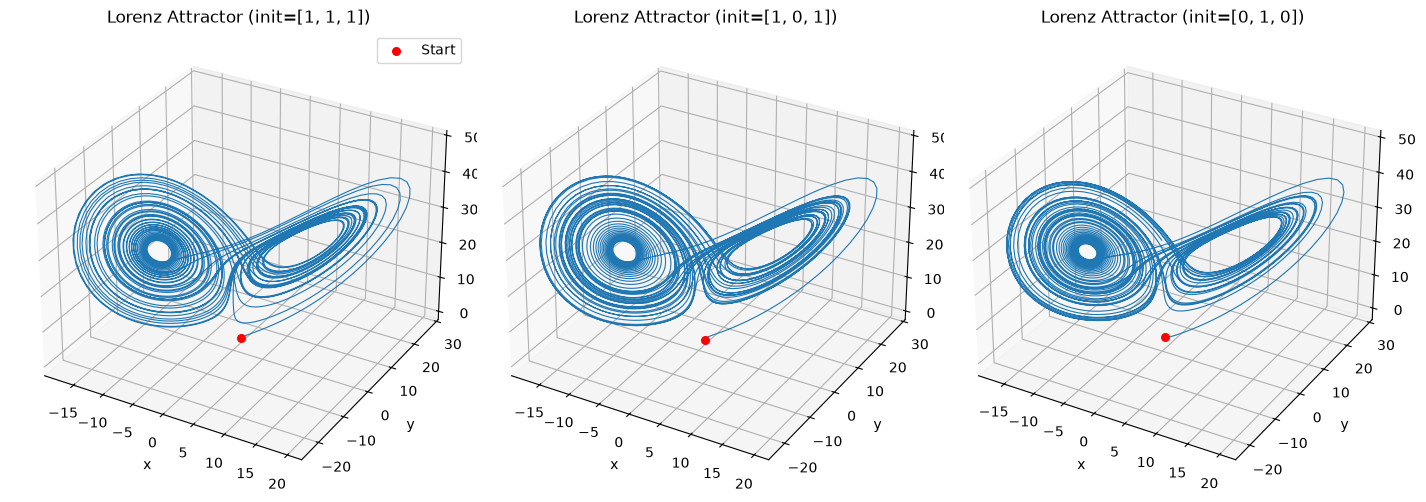

In [59]:
#Initial Conditions:
#tvals: range of time. init: intiial position [x_0, y_0, z_0].
tvals = np.linspace(0, 50, 5000)

inits = [
    [1, 1, 1],
    [1, 0, 1],
    [0, 1, 0],
]

#Solving with these, and plotting

fig, axs = plt.subplots(1, 3, figsize=(14, 5.5), constrained_layout=True, subplot_kw={"projection": "3d"})

for i, (ax, y0) in enumerate(zip(axs, inits)):
    sol = solve_ivp(fun=lorenz, t_span=(0, 50), y0=y0, t_eval=tvals, rtol=1e-9, atol=1e-12)
    x, y, z = sol.y

    ax.plot(x, y, z, lw=0.8)
    ax.scatter([x[0]], [y[0]], [z[0]], color="red", s=30, label="Start")

    ax.set_title(f"Lorenz Attractor (init={y0})")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")
axs[0].legend()

plt.show()

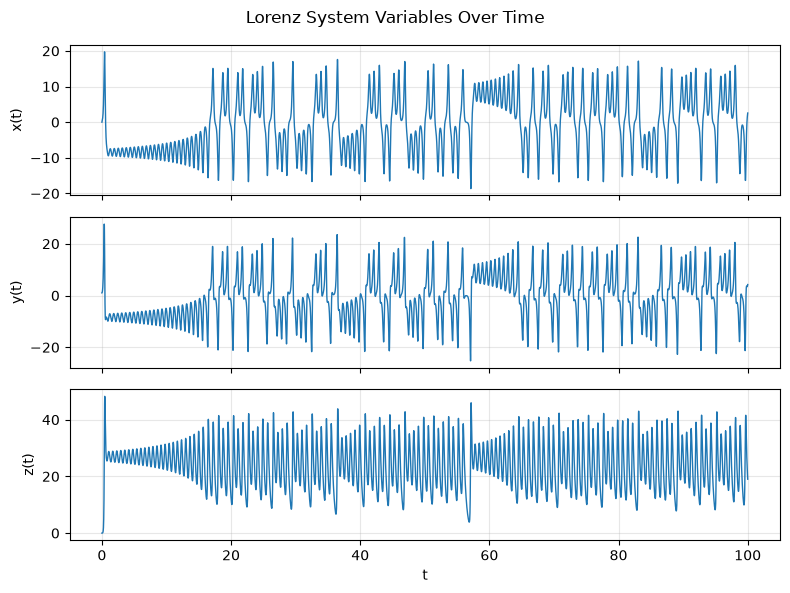

In [60]:
tvals = np.linspace(0, 100, 5000)

init = [1, 1, 1]
sol = solve_ivp(fun=lorenz, t_span=(0, 100), y0=y0, t_eval=tvals, rtol=1e-9, atol=1e-12)

fig, axes = plt.subplots(3, 1, figsize=(8, 6), sharex=True)

labels = ["x(t)", "y(t)", "z(t)"]
for i, ax in enumerate(axes):
    ax.plot(sol.t, sol.y[i], lw=1.0)
    ax.set_ylabel(labels[i])
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("t")
fig.suptitle("Lorenz System Variables Over Time")
plt.tight_layout()
plt.show()